<a href="https://colab.research.google.com/github/Goat-Seller/bankruptcy-prediction/blob/main/logistic_regression_windsor.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [8]:
import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin

class Winsorizer(BaseEstimator, TransformerMixin):
    """Caps extreme outliers at specified lower and upper quantiles fit on training data."""
    def __init__(self, lower_quantile=0.01, upper_quantile=0.99):
        self.lower_quantile = lower_quantile
        self.upper_quantile = upper_quantile

    def fit(self, X, y=None):
        X_df = pd.DataFrame(X)
        self.lower_bounds_ = X_df.quantile(self.lower_quantile)
        self.upper_bounds_ = X_df.quantile(self.upper_quantile)
        return self

    def transform(self, X):
        X_df = pd.DataFrame(X).copy()
        return X_df.clip(lower=self.lower_bounds_, upper=self.upper_bounds_, axis=1).to_numpy()

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, cross_validate, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, recall_score, precision_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay, roc_auc_score)

## dane
data = pd.read_csv('/content/data.csv')

data.columns = data.columns.str.strip()

target = "Bankrupt?"
x = data.drop(columns=[target, "Net Income Flag"])
y = data[target]

x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=44, stratify=y
)

chosen_features = [
    'Persistent EPS in the Last Four Seasons',
    'Total debt/Total net worth',
    'Non-industry income and expenditure/revenue',
    'Net Value Growth Rate',
    'Quick Ratio',
    'Tax rate (A)',
    'Cash/Total Assets',
    'Operating Gross Margin',
]

## winsoryzacja (granice z train)
winsorizer = Winsorizer(lower_quantile=0.01, upper_quantile=0.99)
x_train_w = winsorizer.fit_transform(x_train[chosen_features])
x_test_w = winsorizer.transform(x_test[chosen_features])

## skalowanie
scaler = StandardScaler()
x_train_s_chosen = scaler.fit_transform(x_train_w)
x_test_s_chosen = scaler.transform(x_test_w)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=44)

## 7.1
print("--- 7.1 ---")
clf = LogisticRegression(max_iter=1000, class_weight="balanced")
acc_scores = cross_val_score(clf, x_train_s_chosen, y_train, cv=cv, scoring="accuracy")
print("classification accuracy: ", np.round(acc_scores, 3), "\nmean: ", round(acc_scores.mean(), 3))




--- 7.1 ---
classification accuracy:  [0.874 0.865 0.875 0.859 0.854] 
mean:  0.865


In [10]:
## 7.1
print("--- 7.1 ---")
clf = LogisticRegression(max_iter=1000, class_weight="balanced")
acc_scores = cross_val_score(clf, x_train_s_chosen, y_train, cv=cv, scoring="accuracy")
print("classification accuracy: ", np.round(acc_scores, 3), "\nmean: ", round(acc_scores.mean(), 3))


--- 7.1 ---
classification accuracy:  [0.874 0.865 0.875 0.859 0.854] 
mean:  0.865


## Task 7.2

In [11]:
## 7.2
print("\n--- 7.2 ---")
for k in [3, 5, 10]:
    cv_k = StratifiedKFold(n_splits=k, shuffle=True, random_state=44)
    acc_scores = cross_val_score(clf, x_train_s_chosen, y_train, cv=cv_k, scoring="accuracy")
    print(k, "folds: ", np.round(acc_scores, 3), "\nmean: ", round(acc_scores.mean(), 3))


--- 7.2 ---
3 folds:  [0.864 0.868 0.862] 
mean:  0.865
5 folds:  [0.874 0.865 0.875 0.859 0.854] 
mean:  0.865
10 folds:  [0.879 0.872 0.868 0.861 0.875 0.864 0.846 0.881 0.857 0.855] 
mean:  0.866


## Task 7.3

In [12]:
## 7.3
print("\n--- 7.3 ---")
res = cross_validate(clf, x_train_s_chosen, y_train, cv=cv, scoring=["recall", "precision", "f1"])
print("recall:   ", np.round(res["test_recall"], 3), "\nmean: ", round(res["test_recall"].mean(), 3))
print("precision:", np.round(res["test_precision"], 3), "\nmean: ", round(res["test_precision"].mean(), 3))
print("f1:       ", np.round(res["test_f1"], 3), "\nmean: ", round(res["test_f1"].mean(), 3))



--- 7.3 ---
recall:    [0.889 0.886 0.8   0.886 0.886] 
mean:  0.869
precision: [0.193 0.178 0.178 0.171 0.167] 
mean:  0.177
f1:        [0.317 0.297 0.292 0.287 0.281] 
mean:  0.295


## Task 7.4

In [13]:
## 7.4
print("\n--- 7.4 ---")
clf = LogisticRegression(max_iter=1000)
parameters = {"C": [0.001, 0.01, 0.1, 1, 10, 100], "class_weight": ["balanced"]}

grid_search = GridSearchCV(clf, parameters, cv=cv, scoring="f1", n_jobs=-1)
grid_search.fit(x_train_s_chosen, y_train)

print(grid_search.best_params_)
print(round(grid_search.best_score_, 3))

cv_res = pd.DataFrame(grid_search.cv_results_)
display(cv_res[["param_C", "param_class_weight", "mean_test_score", "rank_test_score"]]
        .sort_values("rank_test_score").round(3))


--- 7.4 ---
{'C': 1, 'class_weight': 'balanced'}
0.295


,param_C,param_class_weight,mean_test_score,rank_test_score
3,1.000,balanced,0.295,1
4,10.000,balanced,0.294,2
5,100.000,balanced,0.294,3
2,0.100,balanced,0.294,4
1,0.010,balanced,0.293,5
0,0.001,balanced,0.282,6


## Task 7.5

In [14]:
## 7.5
print("\n--- 7.5 ---")
best_lr = grid_search.best_estimator_
pred = best_lr.predict(x_test_s_chosen)

print("accuracy: ", round(accuracy_score(y_test, pred), 3))
print("recall:   ", round(recall_score(y_test, pred), 3))
print("precision:", round(precision_score(y_test, pred), 3))
print("f1:       ", round(f1_score(y_test, pred), 3))



--- 7.5 ---
accuracy:  0.85
recall:    0.886
precision: 0.164
f1:        0.277


## Task 7.6 for Linear Regression


--- 7.6 ---
TP: 39 | TN: 1121 | FP: 199 | FN: 5
TPR: 0.886 | TNR: 0.849 | FPR: 0.151 | FNR: 0.114


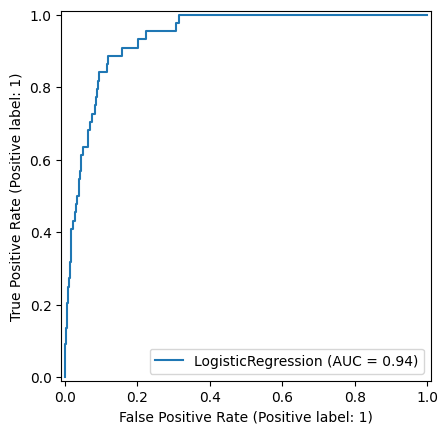

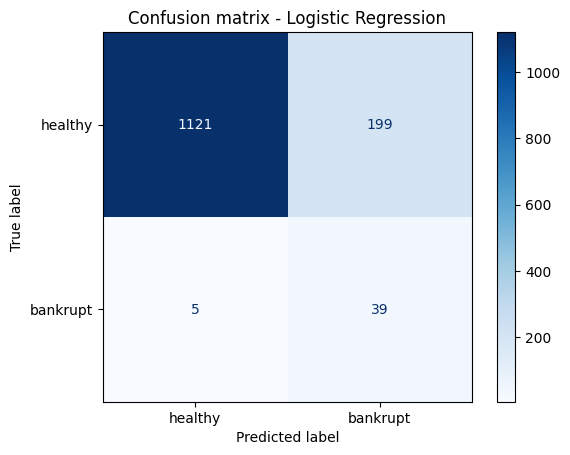

In [15]:
## 7.6
print("\n--- 7.6 ---")
tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
print("TP:", tp, "| TN:", tn, "| FP:", fp, "| FN:", fn)
print("TPR:", round(tp / (tp + fn), 3),
      "| TNR:", round(tn / (tn + fp), 3),
      "| FPR:", round(fp / (fp + tn), 3),
      "| FNR:", round(fn / (fn + tp), 3))

RocCurveDisplay.from_estimator(best_lr, x_test_s_chosen, y_test)
plt.show()

cm = confusion_matrix(y_test, pred)
cm_display = ConfusionMatrixDisplay(cm, display_labels=["healthy", "bankrupt"]).plot(cmap=plt.cm.Blues)
plt.title("Confusion matrix - Logistic Regression")
plt.show()